# **Classification**
#### type of supervised learning. You give the model examples where the right answer is already known, and it learns to predict a category for new examples it has never seen.

## **The core idea**
**Features (X)**: the input information about each example, such as age, income, or the pixels of an image.

**Label (y)**: the category you want to predict, such as “spam” or “not spam”, or a class number like your 0 to 3.

**Training**: the model looks at many labelled examples and finds patterns that link the features to the label. 

**Prediction**: for a new example with no label, the model outputs the class it thinks is most likely.



## **Types of classification**

| Type | What it means | Example |
|---|---|---|
| Binary | Two possible classes | Spam or not spam; fraud or not fraud |
| Multiclass | Three or more classes, with exactly one class per example | Your 4-class problem (0, 1, 2, 3); recognising digits 0–9 |
| Multilabel | An example can have several labels at once | Tagging a photo with “beach”, “sunset” and “people” |

## **The typical workflow**
- Collect labelled data.
- Prepare the features: clean missing values, encode categories as numbers, and scale if the algorithm needs it.
- Split into training and test sets (your test set had 548 rows).
- Train a model on the training set.
- Predict on the test set, which the model has not seen.
- Evaluate the predictions against the true labels, using the metrics you looked at (precision, recall, F1, the confusion matrix).
- Improve: tune the model, add better features, or try a different algorithm.

## **Common algorithms**

| Algorithm | Idea in one line |
|---|---|
| Logistic regression | Draws a boundary between classes and outputs a probability. |
| k-nearest neighbours | Classifies a point by the majority class among its closest neighbours. |
| Decision tree | Asks a series of yes/no questions about features—the algorithm used above. |
| Random forest | Combines many decision trees to make predictions more stable and reduce overfitting. |
| Gradient boosting (XGBoost, LightGBM) | Builds trees sequentially, with each one correcting errors made by earlier trees. Often effective on tabular data. |
| Support vector machine | Finds the boundary with the widest margin between classes. |
| Naive Bayes | Uses probabilities and assumes features are independent. It is fast and commonly used for text. |
| Neural network | Learns patterns through layers and is widely used for images, audio, and text. |

## **What a classifier outputs**

Most models can give you more than a label. predict() returns the chosen class, while predict_proba() returns a probability for each class, for example 70% class 0 and 20% class 1. For binary problems you can change the decision threshold (the default is 0.5) to trade precision against recall, such as flagging more suspicious transactions when missing fraud is costly.

## **Evaluating a classifier**
- **Accuracy**: the share of correct predictions. It is easy to read but misleading when classes are imbalanced.
- **Precision**: when the model predicts a class, how often is it right?
- **Recall**: of the real examples of a class, how many did the model find?
- **F1-score**: a balance of precision and recall.
**Confusion matrix**: shows exactly which classes get mixed up.

## **Common pitfalls**
- **Overfitting**: the model memorises the training data, so it does well on training and badly on new data. Fix it with simpler models, depth limits, regularisation or more data.

- **Class imbalance**: when one class is rare (like your class 2, with 31 of 548 samples), the model may ignore it. Use class_weight, resampling, or metrics beyond accuracy.

- **Data leakage**: information from the test set, or from the future, accidentally reaches the model during training, which makes the results look better than they really are.

- **Poor features:** the best algorithm cannot separate classes that the features do not distinguish. This is likely part of why your classes 0 and 3 get confused.

# **Example**

#### Predicting the position of the player from some features

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder

In [36]:
df = pd.read_csv('classification_data.csv')
df.head(5)

,Rk,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,...,PKatt,CrdY,CrdR,xG,npxG,xAG,npxG+xAG,PrgC,PrgP,PrgR
0,1,Max Aarons,eng ENG,DF,Bournemouth,eng Premier League,24-100,2000,15,12,...,0,1,0,0.0,0.0,0.8,0.8,19,40,22
1,2,Brenden Aaronson,us USA,"MF,FW",Union Berlin,de Bundesliga,23-174,2000,25,10,...,0,3,1,1.7,1.7,1.2,2.9,26,31,56
2,3,Paxten Aaronson,us USA,MF,Eint Frankfurt,de Bundesliga,20-231,2003,7,1,...,0,0,0,0.1,0.1,0.1,0.2,2,5,7
3,4,Yunis Abdelhamid,ma MAR,DF,Reims,fr Ligue 1,36-198,1987,25,25,...,0,4,0,2.4,2.4,0.3,2.7,33,117,7
4,5,Salis Abdul Samed,gh GHA,MF,Lens,fr Ligue 1,24-018,2000,25,17,...,0,2,0,0.8,0.8,0.5,1.3,8,77,20


In [37]:
df.columns

Index(['Rk', 'Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Born', 'MP',
       'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A', 'G-PK', 'PK', 'PKatt',
       'CrdY', 'CrdR', 'xG', 'npxG', 'xAG', 'npxG+xAG', 'PrgC', 'PrgP',
       'PrgR'],
      dtype='str')

In [38]:
# split the position column to get the first position only
df['Pos'] = df['Pos'].apply(lambda x: x.split(',')[0])
df.head(5)

,Rk,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,...,PKatt,CrdY,CrdR,xG,npxG,xAG,npxG+xAG,PrgC,PrgP,PrgR
0,1,Max Aarons,eng ENG,DF,Bournemouth,eng Premier League,24-100,2000,15,12,...,0,1,0,0.0,0.0,0.8,0.8,19,40,22
1,2,Brenden Aaronson,us USA,MF,Union Berlin,de Bundesliga,23-174,2000,25,10,...,0,3,1,1.7,1.7,1.2,2.9,26,31,56
2,3,Paxten Aaronson,us USA,MF,Eint Frankfurt,de Bundesliga,20-231,2003,7,1,...,0,0,0,0.1,0.1,0.1,0.2,2,5,7
3,4,Yunis Abdelhamid,ma MAR,DF,Reims,fr Ligue 1,36-198,1987,25,25,...,0,4,0,2.4,2.4,0.3,2.7,33,117,7
4,5,Salis Abdul Samed,gh GHA,MF,Lens,fr Ligue 1,24-018,2000,25,17,...,0,2,0,0.8,0.8,0.5,1.3,8,77,20


In [39]:
# clean the data by removing any rows where 'Pos' is equal to 'Pos'
df = df.drop(df[df['Pos'] == 'Pos'].index)
df['Pos'].unique()

<StringArray>
['DF', 'MF', 'FW', 'GK']
Length: 4, dtype: str

In [40]:
# clean the data by dropping rows with missing values

df = df.dropna()

In [41]:
df.shape

(2737, 27)

In [42]:
df['Pos'].value_counts()

Pos
DF    977
MF    870
FW    711
GK    179
Name: count, dtype: int64

In [43]:
# Base line Accuracy that we can achieve by predicting the most frequent class
# (0.35696017537449765) means that if we predict the most frequent class for all instances, we will be correct 35.7% of the time. 
# This is a baseline accuracy that we can use to compare our model's performance against.
df['Pos'].value_counts().max() / df['Pos'].value_counts().sum()

np.float64(0.35696017537449765)

In [44]:
# Label encoding Positions to numeric values
label_encoder = LabelEncoder()
df['Pos_Encoded'] = label_encoder.fit_transform(df['Pos'])
df['Pos_Encoded'].unique()


array([0, 3, 1, 2])

In [45]:
print(label_encoder.inverse_transform(df['Pos_Encoded'].unique()))

['DF' 'MF' 'FW' 'GK']


In [46]:
df.columns

Index(['Rk', 'Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Born', 'MP',
       'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A', 'G-PK', 'PK', 'PKatt',
       'CrdY', 'CrdR', 'xG', 'npxG', 'xAG', 'npxG+xAG', 'PrgC', 'PrgP', 'PrgR',
       'Pos_Encoded'],
      dtype='str')

In [47]:
# Filter the data we only need for the classification task
X = df[['Gls', 'Ast', 'G+A', 'G-PK', 'PK', 'PKatt', 'CrdY', 'CrdR', 'xG', 'npxG', 'xAG', 'npxG+xAG', 'PrgC', 'PrgP', 'PrgR']]
y = df['Pos_Encoded']
X.head(5)

,Gls,Ast,G+A,G-PK,PK,PKatt,CrdY,CrdR,xG,npxG,xAG,npxG+xAG,PrgC,PrgP,PrgR
0,0,1,1,0,0,0,1,0,0.0,0.0,0.8,0.8,19,40,22
1,2,0,2,2,0,0,3,1,1.7,1.7,1.2,2.9,26,31,56
2,0,1,1,0,0,0,0,0,0.1,0.1,0.1,0.2,2,5,7
3,3,0,3,3,0,0,4,0,2.4,2.4,0.3,2.7,33,117,7
4,0,0,0,0,0,0,2,0,0.8,0.8,0.5,1.3,8,77,20


In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# **Decision Tree Classifier**

Purple boxes are questions about a feature, and teal boxes are leaves holding a predicted class. To classify a new row, you start at the top, answer each question, follow the branch, and the leaf you land on is the prediction.

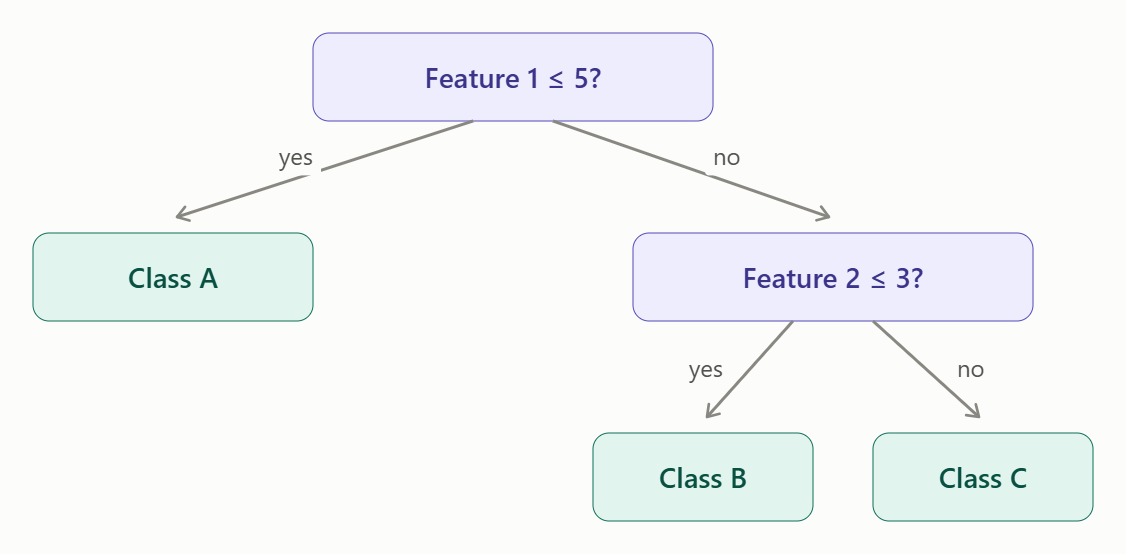

## **How the tree learns**

During training, the tree decides which questions to ask and in what order:

1 - At each node it tries many candidate splits, each being a feature and a threshold (for example, “Feature 1 ≤ 5”).

2 - It picks the split that makes the two resulting groups as pure as possible, meaning each group is mostly one class.

3 - It repeats this on each child group until a stopping rule is hit: the group is pure, the tree reaches max_depth, or there are too few samples to split.

**Purity** is measured with an impurity score. The default is ``Gini impurity: 1 - Σ(pᵢ²)``, where ``pᵢ`` is the share of each class in the group. A group with 5 samples of class 0 and 5 of class 1 scores 1 - (0.25 + 0.25) = 0.5, the worst case for two classes. If a split produces one group with only class 0 and another with only class 1, both score 0, a perfect split. The alternative is criterion="entropy", which behaves similarly.

| Parameter | What it does |
|---|---|
| `max_depth` | Maximum number of question levels. A key way to limit overfitting. |
| `min_samples_split` | Minimum number of samples a node needs before it can split. |
| `min_samples_leaf` | Minimum number of samples allowed in a leaf. |
| `criterion` | Split-quality measure: `"gini"` (default) or `"entropy"`. |
| `class_weight` | Gives classes different weights; `"balanced"` can help with rare classes. |
| `random_state` | Makes results repeatable, including when the algorithm encounters ties between splits. |


## **Strengths and weaknesses**

Decision trees are easy to explain, you can plot or read the exact rules they use, they need no feature scaling, and they capture non-linear patterns. Their main weakness is overfitting. With no limits, a tree keeps splitting until every leaf is pure, which means it memorises the training data, noise included. They are also unstable, because small changes in the data can produce a very different tree. Random forests exist to fix this by averaging many trees.

Classification report fits this picture. A tree with moderate accuracy (61%) and uneven precision and recall per class often comes from the depth settings, from class_weight, or from classes that overlap in the features.


In [53]:
# Use a Decision Tree Classifier to fit the model
cls = DecisionTreeClassifier()
cls.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [54]:
# Make predictions on the test set
y_pred = cls.predict(X_test)

# Calculate the accuracy of the model
accuracy = accuracy_score(y_test, y_pred)
accuracy

0.6076642335766423

In [55]:
# Calculate the confusion matrix
confusion = confusion_matrix(y_test, y_pred)
confusion

array([[119,  11,  11,  60],
       [ 14,  85,   5,  30],
       [  0,   0,  29,   2],
       [ 45,  28,   9, 100]])

## Reading the matrix
- Rows are the actual class, and columns are the predicted class.
- The diagonal (119, 83, 29, 102) holds the correct predictions.
Everything off the diagonal is a mistake. For example, the 61 in row 0, column 3 means 61 samples that were truly class 0 were predicted as class 3.

In [56]:
# Calculate the classification report
class_report = classification_report(y_test, y_pred)
print(class_report)

              precision    recall  f1-score   support

           0       0.67      0.59      0.63       201
           1       0.69      0.63      0.66       134
           2       0.54      0.94      0.68        31
           3       0.52      0.55      0.53       182

    accuracy                           0.61       548
   macro avg       0.60      0.68      0.63       548
weighted avg       0.62      0.61      0.61       548



## Notes from the model
**Precision**: of everything the model predicted as a class, how much was correct. For class 0, 68% of the “0” predictions were truly 0.

**Recall**: of all the real examples of a class, how many the model found. For class 0, it found 59% of the true 0s.

**F1-score**: a single number that balances precision and recall (their harmonic mean). It is low if either one is low.

**Support**: how many real examples of each class are in the test set.

## The overall rows

**Accuracy** (0.61): 61% of all predictions were correct. A model that always predicted the biggest class (0) would score about 37% (201 of 548), and random guessing across four classes would score about 25%. So 61% is meaningfully better than those baselines, but far from strong.

**Macro avg**: the plain average across classes, so every class counts equally. Recall is 0.68 here, higher than accuracy, because the very good class 2 recall counts as much as the big classes.

**Weighted avg**: the average weighted by support, so large classes count more. It is close to the accuracy number (0.61 to 0.62), as expected.

#### **Recall** answers: of all the real examples of this class, how many did the model find?
| Metric | Question it answers | Formula | Class 0 example | Class 2 example |
| --- | --- | --- | --- | --- |
| Recall | Of all the real examples of this class, how many did the model find? | correct predictions of the class ÷ class row total | 119 ÷ 201 = 0.59 | 29 ÷ 31 = 0.94 |
| Precision | When the model predicts this class, how often is it right? | correct predictions of the class ÷ class column total | 119 ÷ (119 + 15 + 0 + 41) = 0.68 | 29 ÷ (11 + 5 + 29 + 9) = 0.54 |
| F1-score | How well do precision and recall balance each other? | 2 × (precision × recall) ÷ (precision + recall) | 2 × (0.68 × 0.59) ÷ (0.68 + 0.59) = 0.63 | 2 × (0.54 × 0.94) ÷ (0.54 + 0.94) = 0.68 |
| Support | How many real examples of the class are in the test set? | sum of that class’s row | 201 | 31 |

**High recall means “it rarely misses this class.”**  
**High precision means “when it says this class, you can trust it.”**  
**The harmonic mean punishes imbalance, so a model with very high precision but poor recall will still have a weak F1-score.**
**Support tells you how much to trust a score. Class 2 has only 31 samples, so its numbers can swing a lot from a few errors.**
